# 不计分实验 - 树集成

在本 notebook 中，你将：

 - 使用 Pandas 对数据集进行独热编码
 - 使用 scikit-learn 实现决策树、随机森林和 XGBoost 模型

让我们导入将要用到的库。

In [1]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
plt.style.use('./deeplearning.mplstyle')

RANDOM_STATE = 55 ## We will pass it to every sklearn call so we ensure reproducibility

# 1. 介绍

#### 数据集
- 该数据集来自 Kaggle：[Heart Failure Prediction Dataset](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction)

#### 背景
- 心血管疾病（CVD）是全球头号死因，每年估计夺走 1790 万人的生命，占全球死亡总数的 31%。五分之四的 CVD 死亡由心脏病发作和中风导致，且其中三分之一的死亡过早发生在 70 岁以下的人群中。心力衰竭是 CVD 引起的常见事件。
- 患有心血管疾病或处于高心血管风险（由于存在高血压、糖尿病、高脂血症或已确诊疾病等一个或多个风险因素）的人群需要及早发现和管理。  
- 该数据集包含 11 个可用于预测潜在心脏病的特征。
- 让我们训练一个机器学习模型来辅助诊断这种疾病。

#### 属性信息
- Age：患者年龄 [岁]
- Sex：患者性别 [M：男，F：女]
- ChestPainType：胸痛类型 [TA：典型心绞痛，ATA：非典型心绞痛，NAP：非心绞痛，ASY：无症状]
- RestingBP：静息血压 [mm Hg]
- Cholesterol：血清胆固醇 [mm/dl]
- FastingBS：空腹血糖 [1：空腹血糖 > 120 mg/dl，0：否则]
- RestingECG：静息心电图结果 [Normal：正常，ST：有 ST-T 波异常（T 波倒置和/或 ST 段抬高或压低 > 0.05 mV），LVH：按 Estes 标准显示可能或确定的左心室肥厚]
- MaxHR：达到的最大心率 [60 到 202 之间的数值]
- ExerciseAngina：运动诱发的心绞痛 [Y：是，N：否]
- Oldpeak：oldpeak = ST [以压低程度衡量的数值]
- ST_Slope：运动峰值 ST 段的斜率 [Up：向上倾斜，Flat：平坦，Down：向下倾斜]
- HeartDisease：输出类别 [1：心脏病，0：正常]

现在加载数据集。如上所示，以下变量：

- Sex
- ChestPainType
- RestingECG
- ExerciseAngina
- ST_Slope

是*类别型*变量，因此必须对它们进行独热编码。

In [2]:
# 使用 pandas 加载数据集
df = pd.read_csv("heart.csv")

In [3]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


在使用模型之前，我们必须进行一些数据工程处理。共有 5 个类别型特征，我们将使用 Pandas 对它们进行独热编码。

## 2. 使用 Pandas 进行独热编码

首先我们会移除二值变量，因为对它们进行独热编码不会带来任何变化。做法是统计每个类别变量中不同取值的数量，只保留取值有 3 个或以上的变量。

In [4]:
cat_variables = ['Sex',
'ChestPainType',
'RestingECG',
'ExerciseAngina',
'ST_Slope'
]

提醒一下，独热编码的目标是把一个有 `n` 种取值的类别变量转换成 `n` 个二值变量。

Pandas 内置了独热编码方法，即 `pd.get_dummies` 函数。该函数有多个参数，但这里我们只用其中几个：

 - data：要使用的 DataFrame
 - prefix：前缀列表，便于我们知道正在处理哪个取值
 - columns：要进行独热编码的列名列表。'prefix' 和 'columns' 的长度必须相同。
 
如需了解更多，随时可以输入 `help(pd.get_dummies)` 查看该函数的完整文档。

In [5]:
# 这会用独热编码后的列替换原来的列，'columns' 参数之外的列保持不变。
df = pd.get_dummies(data = df, prefix = cat_variables, columns = cat_variables)

In [6]:
df.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_F,Sex_M,ChestPainType_ASY,...,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,0,False,True,False,...,False,False,False,True,False,True,False,False,False,True
1,49,160,180,0,156,1.0,1,True,False,False,...,True,False,False,True,False,True,False,False,True,False
2,37,130,283,0,98,0.0,0,False,True,False,...,False,False,False,False,True,True,False,False,False,True
3,48,138,214,0,108,1.5,1,True,False,True,...,False,False,False,True,False,False,True,False,True,False
4,54,150,195,0,122,0.0,0,False,True,False,...,True,False,False,True,False,True,False,False,False,True


我们来选择将作为模型输入特征的变量。
- 目标是 `HeartDisease`。
- 其余所有变量都是可用于预测目标 `HeartDisease` 的潜在特征。

In [7]:
features = [x for x in df.columns if x not in 'HeartDisease'] ## Removing our target variable

我们从 11 个特征开始。来看看独热编码之后有多少个特征变量。

In [8]:
print(len(features))

20


# 3. 划分数据集

本节中，我们将把数据集划分为训练集和测试集。我们将使用 Scikit-learn 的 `train_test_split` 函数。先来看看它的参数。

In [9]:
help(train_test_split)

Help on function train_test_split in module sklearn.model_selection._split:

train_test_split(*arrays, test_size=None, train_size=None, random_state=None, shuffle=True, stratify=None)
    Split arrays or matrices into random train and test subsets.

    Quick utility that wraps input validation,
    ``next(ShuffleSplit().split(X, y))``, and application to input data
    into a single call for splitting (and optionally subsampling) data into a
    one-liner.

    Read more in the :ref:`User Guide <cross_validation>`.

    Parameters
    ----------
    *arrays : sequence of array-like of shape (n_samples,) or             (n_samples, n_outputs)
        Indexable data-structures can be arrays, lists, dataframes, scipy
        sparse matrices or pandas dataframes with consistent first dimension.

    test_size : float or int, default=None
        If float, should be between 0.0 and 1.0 and represent the proportion
        of the dataset to include in the test split. If int, represents the
 

In [10]:
X_train, X_val, y_train, y_val = train_test_split(df[features], df['HeartDisease'], train_size = 0.8, random_state = RANDOM_STATE)

# 我们保留 shuffle = True，因为我们的数据集没有任何时间依赖关系。

In [11]:
print(f'train samples: {len(X_train)} validation samples: {len(X_val)}')
print(f'target proportion: {sum(y_train)/len(y_train):.4f}')

train samples: 734 validation samples: 184
target proportion: 0.5518


# 4. 构建模型

## 4.1 决策树

本节中，我们使用之前学过的决策树，但这次使用 [Scikit-learn 的实现](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)。 

Scikit-learn 的决策树对象中有多个超参数。我们只会使用其中一部分，并且本实验中不进行特征选择或超参数调优（但鼓励你自行尝试并比较结果 😄 ）

我们这里将使用并研究的超参数是：

 - min_samples_split：划分内部节点所需的最小样本数。 
   - 选择更大的 min_samples_split 可以减少划分次数，有助于减少过拟合。
 - max_depth：树的最大深度。 
   - 选择更小的 max_depth 可以减少划分次数，有助于减少过拟合。

In [12]:
min_samples_split_list = [2,10, 30, 50, 100, 200, 300, 700] ## If the number is an integer, then it is the actual quantity of samples,
max_depth_list = [1,2, 3, 4, 8, 16, 32, 64, None] # None means that there is no depth limit.

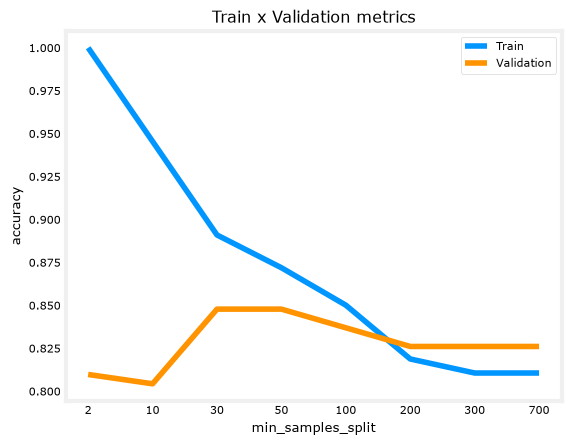

In [13]:
accuracy_list_train = []
accuracy_list_val = []
for min_samples_split in min_samples_split_list:
    # 你可以在定义模型的同时完成拟合，因为 fit 函数会返回拟合好的估计器。
    model = DecisionTreeClassifier(min_samples_split = min_samples_split,
                                   random_state = RANDOM_STATE).fit(X_train,y_train) 
    predictions_train = model.predict(X_train) ## The predicted values for the train dataset
    predictions_val = model.predict(X_val) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_val = accuracy_score(predictions_val,y_val)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_val.append(accuracy_val)

plt.title('Train x Validation metrics')
plt.xlabel('min_samples_split')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(min_samples_split_list )),labels=min_samples_split_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_val)
plt.legend(['Train','Validation'])

注意增大 `min_samples_split` 如何减少过拟合。
- 将 `min_samples_split` 从 10 增大到 30、再从 30 增大到 50，虽然并没有提升验证集准确率，但让训练集准确率更接近它，表明过拟合有所减少。

我们对 `max_depth` 做同样的实验。

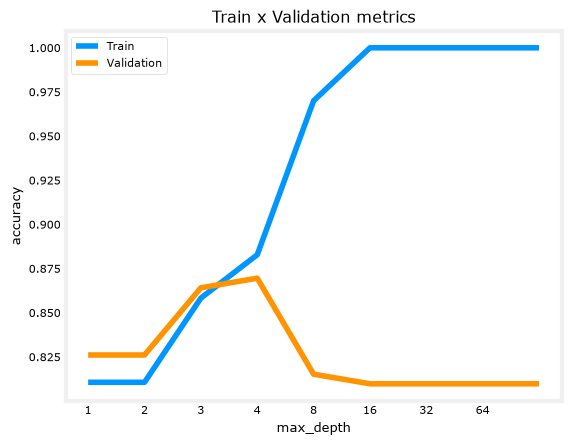

In [14]:
accuracy_list_train = []
accuracy_list_val = []
for max_depth in max_depth_list:
    # 你可以在定义模型的同时完成拟合，因为 fit 函数会返回拟合好的估计器。
    model = DecisionTreeClassifier(max_depth = max_depth,
                                   random_state = RANDOM_STATE).fit(X_train,y_train) 
    predictions_train = model.predict(X_train) ## The predicted values for the train dataset
    predictions_val = model.predict(X_val) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_val = accuracy_score(predictions_val,y_val)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_val.append(accuracy_val)

plt.title('Train x Validation metrics')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(max_depth_list )),labels=max_depth_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_val)
plt.legend(['Train','Validation'])

可以看到，总体上减小 `max_depth` 有助于减少过拟合。
- 将 `max_depth` 从 8 减小到 4，验证集准确率更接近训练集准确率，同时训练集准确率显著下降。
- 验证集准确率在 tree_depth=4 时达到最高。 
- 当 `max_depth` 小于 3 时，训练集和验证集准确率都会下降。树无法进行足够的划分来区分正例和负例（模型对训练集欠拟合）。 
- 当 `max_depth` 过大（ >= 5 ）时，验证集准确率下降而训练集准确率上升，表明模型对训练集过拟合。

因此我们可以为模型选择这两个超参数的最佳值：
- `max_depth = 4`
- `min_samples_split = 50`

In [15]:
decision_tree_model = DecisionTreeClassifier(min_samples_split = 50,
                                             max_depth = 3,
                                             random_state = RANDOM_STATE).fit(X_train,y_train)

In [16]:
print(f"Metrics train:\n\tAccuracy score: {accuracy_score(decision_tree_model.predict(X_train),y_train):.4f}")
print(f"Metrics validation:\n\tAccuracy score: {accuracy_score(decision_tree_model.predict(X_val),y_val):.4f}")

Metrics train:
	Accuracy score: 0.8583
Metrics validation:
	Accuracy score: 0.8641


没有过拟合的迹象，尽管指标并不算好。

## 4.2 随机森林

现在我们也来试试随机森林算法，同样使用 Scikit-learn 的实现。 
- 决策树模型中的所有超参数在这个算法中也存在，因为随机森林就是由许多决策树组成的集成。
- 随机森林额外的一个超参数叫 `n_estimators`，即组成随机森林的决策树数量。 

记住，对于随机森林，我们会随机选择一部分特征，并且随机选择一部分训练样本来训练每一棵树。
- 按照课程所讲，如果 $n$ 是特征数量，我们将随机选取 $\sqrt{n}$ 个特征来训练每一棵树。 
- 注意你可以通过设置 `max_features` 参数来修改这一点。

你还可以用另一个参数 `n_jobs` 来加速训练任务。 
- 由于每棵树的拟合相互独立，可以并行拟合多棵树。 
- 因此把 `n_jobs` 设得更高会增加使用的 CPU 核心数。注意，接近 CPU 最大核心数的取值可能会影响电脑的整体性能，甚至导致卡死。 
- 修改这个参数不会影响最终结果，但可以缩短训练时间。

我们将再次运行同样的脚本，但换用另一个参数 `n_estimators`，在 10、50 和 100 之间选择。默认值是 100。

In [17]:
min_samples_split_list = [2,10, 30, 50, 100, 200, 300, 700]  ## If the number is an integer, then it is the actual quantity of samples,
                                             # # 如果是浮点数，则表示数据集的比例
max_depth_list = [2, 4, 8, 16, 32, 64, None]
n_estimators_list = [10,50,100,500]

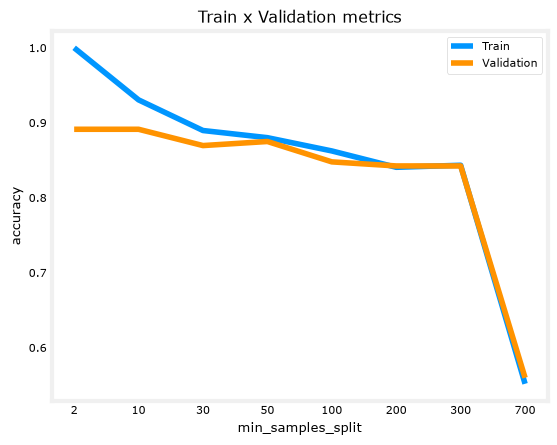

In [18]:
accuracy_list_train = []
accuracy_list_val = []
for min_samples_split in min_samples_split_list:
    # 你可以在定义模型的同时完成拟合，因为 fit 函数会返回拟合好的估计器。
    model = RandomForestClassifier(min_samples_split = min_samples_split,
                                   random_state = RANDOM_STATE).fit(X_train,y_train) 
    predictions_train = model.predict(X_train) ## The predicted values for the train dataset
    predictions_val = model.predict(X_val) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_val = accuracy_score(predictions_val,y_val)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_val.append(accuracy_val)

plt.title('Train x Validation metrics')
plt.xlabel('min_samples_split')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(min_samples_split_list )),labels=min_samples_split_list) 
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_val)
plt.legend(['Train','Validation'])

注意，尽管验证集准确率在 `min_samples_split = 2` 和 `min_samples_split = 10` 时相同，但后者训练集和验证集的差距缩小了，表明过拟合更少。

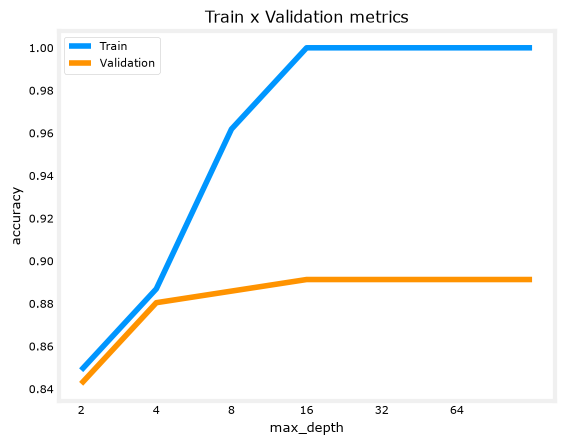

In [19]:
accuracy_list_train = []
accuracy_list_val = []
for max_depth in max_depth_list:
    # 你可以在定义模型的同时完成拟合，因为 fit 函数会返回拟合好的估计器。
    model = RandomForestClassifier(max_depth = max_depth,
                                   random_state = RANDOM_STATE).fit(X_train,y_train) 
    predictions_train = model.predict(X_train) ## The predicted values for the train dataset
    predictions_val = model.predict(X_val) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_val = accuracy_score(predictions_val,y_val)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_val.append(accuracy_val)

plt.title('Train x Validation metrics')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(max_depth_list )),labels=max_depth_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_val)
plt.legend(['Train','Validation'])

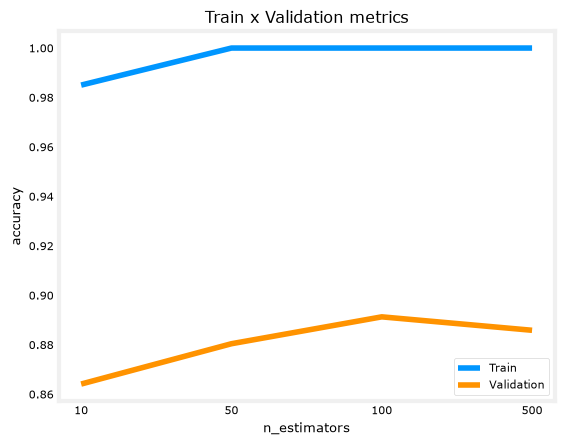

In [20]:
accuracy_list_train = []
accuracy_list_val = []
for n_estimators in n_estimators_list:
    # 你可以在定义模型的同时完成拟合，因为 fit 函数会返回拟合好的估计器。
    model = RandomForestClassifier(n_estimators = n_estimators,
                                   random_state = RANDOM_STATE).fit(X_train,y_train) 
    predictions_train = model.predict(X_train) ## The predicted values for the train dataset
    predictions_val = model.predict(X_val) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_val = accuracy_score(predictions_val,y_val)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_val.append(accuracy_val)

plt.title('Train x Validation metrics')
plt.xlabel('n_estimators')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(n_estimators_list )),labels=n_estimators_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_val)
plt.legend(['Train','Validation'])

那么，我们用以下参数拟合一个随机森林：

 - max_depth：16
 - min_samples_split：10
 - n_estimators：100

In [21]:
random_forest_model = RandomForestClassifier(n_estimators = 100,
                                             max_depth = 16, 
                                             min_samples_split = 10).fit(X_train,y_train)

In [22]:
print(f"Metrics train:\n\tAccuracy score: {accuracy_score(random_forest_model.predict(X_train),y_train):.4f}\nMetrics test:\n\tAccuracy score: {accuracy_score(random_forest_model.predict(X_val),y_val):.4f}")

Metrics train:
	Accuracy score: 0.9319
Metrics test:
	Accuracy score: 0.8804


注意，我们每次只调整一个超参数来寻找最佳值，其余超参数保持默认值。
- 理想情况下，我们会检查每个待调超参数的所有取值组合。
- 如果有 3 个超参数，每个超参数有 4 个候选值，那么总共应该有 4 x 4 x 4 = 64 种组合要尝试。
- 而当我们只修改一个超参数、其余保持默认值时，我们尝试的是 4 + 4 + 4 = 12 种结果。 
- 要尝试所有组合，可以使用 sklearn 的 GridSearchCV 实现。GridSearchCV 有一个 refit 参数，会自动用最佳组合重新拟合模型，因此我们不需要显式编写这部分代码。更多关于 GridSearchCV 的内容，请参阅其[文档](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)。

## 4.3 XGBoost

接下来是梯度提升模型 XGBoost。提升方法同样训练多棵树，但各树之间不再互不相关，而是一棵接一棵地拟合，以不断最小化误差。 

该模型的参数与决策树相同，外加学习率。
- 学习率是 XGBoost 内部使用梯度下降法在每个训练步中最小化误差的步长。

XGBoost 的一个有趣之处在于，拟合时可以传入形如 `(X_val,y_val)` 的评估数据集。
- 每次迭代，它都会在评估数据集上衡量代价（或评估指标）。
- 一旦代价（或指标）连续若干轮（称为 early_stopping_rounds）不再下降，训练就会停止。 
- 迭代越多，估计器越多，而估计器过多可能导致过拟合。  
- 通过在验证指标不再提升时停止，我们可以限制创建的估计器数量，从而减少过拟合。

首先，定义训练集的一个子集（这里不应使用测试集）。

In [23]:
n = int(len(X_train)*0.8) ## Let's use 80% to train and 20% to eval

In [24]:
X_train_fit, X_train_eval, y_train_fit, y_train_eval = X_train[:n], X_train[n:], y_train[:n], y_train[n:]

然后我们可以设置一个很大的估计器数量，因为一旦代价函数停止下降就可以停下来。

注意 `.fit()` 的一些参数：
- `eval_set = [(X_train_eval,y_train_eval)]`：这里必须向 eval_set 传入一个列表，因为你可以有多个不同的评估集元组。 
- `early_stopping_rounds`：该参数让模型在验证集上的评估指标不再提升时停止训练。这里设为 10。
  - 模型会记录表现最佳（评估指标最低）的那一轮。例如，假设第 16 轮取得了目前最低的评估指标。
  - 后续每一轮的评估指标都会与最佳指标比较。如果连续 10 轮都没有优于最佳指标，模型就停止训练。
  - 返回的是训练终止时最后一轮状态的模型，而不是最佳轮次的状态。例如，如果模型在第 26 轮停止，而最佳轮是第 16 轮，返回的是第 26 轮的训练状态，而不是第 16 轮。
  - 注意，这与返回模型的“最佳”状态（评估指标最低时的状态）不同。

In [25]:
xgb_model = XGBClassifier(n_estimators = 500, learning_rate = 0.1, verbosity = 1, random_state = RANDOM_STATE, early_stopping_rounds = 10)
xgb_model.fit(X_train_fit,y_train_fit, eval_set = [(X_train_eval,y_train_eval)])

[0]	validation_0-logloss:0.63302


[1]	validation_0-logloss:0.59554


[2]	validation_0-logloss:0.56614


[3]	validation_0-logloss:0.54187


[4]	validation_0-logloss:0.52349


...

[24]	validation_0-logloss:0.44843


[25]	validation_0-logloss:0.45337


[26]	validation_0-logloss:0.45206


[27]	validation_0-logloss:0.45435


,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,10
,enable_categorical,False
,eval_metric,None
,feature_types,None


尽管我们初始化模型时允许最多 500 个估计器，但算法只拟合了 26 个估计器（超过 26 轮训练）。

要知道原因，我们来找出表现最佳（评估指标最低）的训练轮次。你可以查看上面输出的验证 log loss 指标，或者查看模型的 `.best_iteration` 属性：

In [26]:
xgb_model.best_iteration

17

最佳训练轮次是第 16 轮，log loss 为 4.3948。  
- 在那之后的 10 轮训练中（第 17 到 26 轮），log loss 都高于这个值。
- 由于我们将 `early_stopping_rounds` 设为 10，到第 10 轮 log loss 没有优于最佳值时，训练停止。
- 你可以尝试不同的 `early_stopping_rounds` 取值来验证这一点。例如设为 20，模型会在第 36 轮（16 + 20）停止训练。

In [27]:
print(f"Metrics train:\n\tAccuracy score: {accuracy_score(xgb_model.predict(X_train),y_train):.4f}\nMetrics test:\n\tAccuracy score: {accuracy_score(xgb_model.predict(X_val),y_val):.4f}")

Metrics train:
	Accuracy score: 0.9319
Metrics test:
	Accuracy score: 0.8533


在这个例子中，随机森林和 XGBoost 的表现（测试集准确率）相近。  

恭喜，你已经学会了如何使用 scikit-learn 库中的决策树、随机森林以及 XGBoost！